<a href="https://colab.research.google.com/github/Kuper994/Software-Project/blob/main/numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Numpy

Numpy is the core library for scientific computing in Python. It provides a high-performance multidimensional array object, and tools for working with these arrays.

## Setup

NumPy and Matplotlib are already installed in the course Docker image (see `requirements.txt`); on another machine, run `pip install numpy matplotlib` in a terminal. Run this cell first: it imports the libraries under their usual names `np` and `plt`, and defines two small helpers used below.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def title(text, *values):
    # print the explanation in bold, then the values unchanged:
    # "\033[1m" turns bold on, "\033[0m" turns it off
    print("\033[1m" + text + "\033[0m", *values)

def topic(name, formula):
    # show a bold name, then its formula rendered as LaTeX
    display(Markdown(f"**{name}**\n\n$${formula}$$"))

## N-dimensional Arrays

We can initialize numpy arrays from nested Python lists, and access elements using square brackets:

In [2]:
a = np.array([1, 2, 3])  # Create 1-dimensional array
title("Type of array:", type(a))
title("Dimensions:", a.shape)
title("Elements:", a[0], a[1], a[2])
a[0] = 5                 # Change an element of the array
print(a)

Type of array: <class 'numpy.ndarray'>
Dimensions: (3,)
Elements: 1 2 3
[5 2 3]


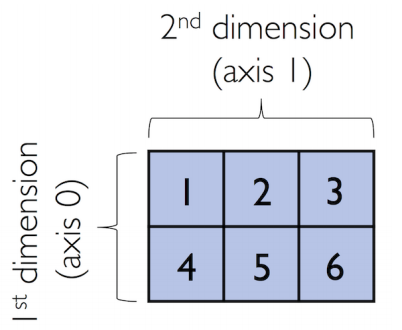

A NumPy array has type `numpy.ndarray`, short for *n-dimensional array*. It is a grid of values, all of the same type, indexed by a tuple of non-negative integers. The number of dimensions is `ndim`; the **shape** is a tuple with the size of the array along each dimension.

In [3]:
b = np.array([[1,2,3],[4,5,6]])   # a 2-dimensional array
title("b:")
print(b)

# Type, shape, size and number of dimensions
title("type of b:", type(b))
title("shape of b:", b.shape)
title("number of elements in b:", b.size)
title("number of dimensions of b:", b.ndim)

# Indexing a 2-D array with [row, column]
title("b[0, 0], b[0, 1], b[1, 0]:", b[0, 0], b[0, 1], b[1, 0])

# The data type is inferred from the values when the array is created:
# one float in the list makes every element a float
title("data type of b:", b.dtype)
c = np.array([[1.2,2,3],[4,5.3,6]])
title("data type of c:", c.dtype)

# Functions can work along one dimension; axis=0 sums down the rows
title("sum of each column of b:", np.sum(b, axis=0))

b:
[[1 2 3]
 [4 5 6]]
type of b: <class 'numpy.ndarray'>
shape of b: (2, 3)
number of elements in b: 6
number of dimensions of b: 2
b[0, 0], b[0, 1], b[1, 0]: 1 2 4
data type of b: int64
data type of c: float64
sum of each column of b: [5 7 9]


Numpy also provides many array construction routines:

In [4]:
a = np.zeros((2,3))          # Create an array of all zeros
title("All-zeros array:")
print(a)
b = np.ones((1,2))           # Create an array of all ones
title("All-ones array:")
print(b)
c = np.full((2,2), 7)        # Create a constant array
title("Constant array:")
print(c)
d = np.eye(3)                # Create a 3x3 identity matrix
title("Identity matrix:")
print(d)
e = np.random.random((2,2))  # Create an array filled with random values
title("Random array:")
print(e)
f = np.arange(1., 11., 2)    # similar to Python's range
title("Evenly spaced values:")
print(f)

All-zeros array:
[[0. 0. 0.]
 [0. 0. 0.]]
All-ones array:
[[1. 1.]]
Constant array:
[[7 7]
 [7 7]]
Identity matrix:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
Random array:
[[0.67916523 0.06436157]
 [0.26757561 0.44306833]]
Evenly spaced values:
[1. 3. 5. 7. 9.]


## Array indexing

In this section, we will go over the basics of retrieving NumPy array elements via different
indexing methods. Simple NumPy indexing and slicing works similar to Python lists.

Slicing: Similar to Python lists, numpy arrays can be sliced. Since arrays may be multidimensional, you must specify a slice for each dimension of the array.

A slice of an array is a **view** into the same data, not a copy, so modifying the slice also modifies the original array.

In [5]:
# Create a rank 2 array with shape (3, 4)
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])
title("a:")
print(a)

# Slice out the first 2 rows and columns 1 and 2; b has shape (2, 2)
b = a[:2, 1:3]
title("b = a[:2, 1:3] ")
print(b)

# b is a view: b[0, 0] and a[0, 1] are the same piece of data
title("a[0, 1] before the assignment:", a[0, 1])
b[0, 0] = 77
title("a[0, 1] after the assignment", a[0, 1])


a:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
b = a[:2, 1:3] 
[[2 3]
 [6 7]]
a[0, 1] before the assignment: 2
a[0, 1] after the assignment 77


### Ways to index an array

For a 2-D array `a`, you index with one entry per dimension: `a[rows, columns]`. Each entry can be one of three kinds, and the kind decides the shape of the result and whether you get a view or a copy.

| Index kind | Example | Result | View or copy? |
|---|---|---|---|
| **Integer** | `a[1, 2]`, `a[1, :]` | The dimension indexed by an integer **disappears**: `a[1, :]` is 1-D, shape `(4,)` | View |
| **Slice** `start:stop` | `a[1:2, :]`, `a[:, 1:2]` | The dimension is **kept** (here with length 1): `a[1:2, :]` is 2-D, shape `(1, 4)` | View |
| **Integer array** (a list or array of indices) | `a[[0, 1, 2], [0, 1, 0]]` | Picks arbitrary elements: the i-th row index is paired with the i-th column index | **Copy** |

So `a[1, :]` and `a[1:2, :]` contain the same numbers but have different ranks, and `a[[1], :]` has the same shape as `a[1:2, :]` but is a copy, so changing it does not change `a`.

Integer array indexing is not limited to sub-blocks: `a[[0, 1, 2], [0, 1, 0]]` returns the elements `a[0, 0]`, `a[1, 1]`, `a[2, 0]`, and the same element may be picked more than once. A fourth kind, boolean indexing, is covered in the Filtering section below.

In [6]:
# Create the following rank 2 array with shape (3, 4)
a = np.array([[1,2,3,4], [5,6,7,8], [9,10,11,12]])
print(a)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]


In [7]:
# 1) Rows: an integer index drops the dimension, a slice keeps it
row_r1 = a[1, :]    # integer + slice    -> rank 1 view
row_r2 = a[1:2, :]  # slice + slice      -> rank 2 view
row_r3 = a[[1], :]  # integer array      -> rank 2 copy
title("a[1, :]   ->", row_r1, "shape", row_r1.shape)
title("a[1:2, :] ->", row_r2, "shape", row_r2.shape)
title("a[[1], :] ->", row_r3, "shape", row_r3.shape)

# 2) Columns: the same distinction
col_r1 = a[:, 1]
col_r2 = a[:, 1:2]
title("a[:, 1]   ->", col_r1, "shape", col_r1.shape)
title("a[:, 1:2] ->", col_r2.tolist(), "shape", col_r2.shape)

# 3) Integer array indexing: pair up row and column indices
title("a[[0, 1, 2], [0, 1, 0]] ->", a[[0, 1, 2], [0, 1, 0]])
title("a[[0, 0], [1, 1]]       ->", a[[0, 0], [1, 1]])

a[1, :]   -> [5 6 7 8] shape (4,)
a[1:2, :] -> [[5 6 7 8]] shape (1, 4)
a[[1], :] -> [[5 6 7 8]] shape (1, 4)
a[:, 1]   -> [ 2  6 10] shape (3,)
a[:, 1:2] -> [[2], [6], [10]] shape (3, 1)
a[[0, 1, 2], [0, 1, 0]] -> [1 6 9]
a[[0, 0], [1, 1]]       -> [2 2]


In [8]:
# A useful trick: select, then change, one element from each row
a = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
b = np.array([0, 2, 0, 1])        # the column to take from each row
title("a:")
print(a)

title("a[np.arange(4), b]:", a[np.arange(4), b])
a[np.arange(4), b] += 10
title("a after a[np.arange(4), b] += 10:")
print(a)

a:
[[ 1  2  3]
 [ 4  5  6]
 [ 7  8  9]
 [10 11 12]]
a[np.arange(4), b]: [ 1  6  7 11]
a after a[np.arange(4), b] += 10:
[[11  2  3]
 [ 4  5 16]
 [17  8  9]
 [10 21 12]]


### Your turn: predict the shape

`a = np.arange(12).reshape(3, 4)` is a $3 \times 4$ array. **Before running the cell, predict the shape of each result:**

1. `a[2]`
2. `a[:, 3]`
3. `a[:, 3:]`
4. `a[1:, 1:3]`
5. `a[[0, 2]]`

Then run the cell and check your predictions.

In [9]:
a = np.arange(12).reshape(3, 4)
title("a:")
print(a)
print()
title("a[2]       shape", a[2].shape)
title("a[:, 3]    shape", a[:, 3].shape)
title("a[:, 3:]   shape", a[:, 3:].shape)
title("a[1:, 1:3] shape", a[1:, 1:3].shape)
title("a[[0, 2]]  shape", a[[0, 2]].shape)

a:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

a[2]       shape (4,)
a[:, 3]    shape (3,)
a[:, 3:]   shape (3, 1)
a[1:, 1:3] shape (2, 2)
a[[0, 2]]  shape (2, 4)


An integer index removes its dimension: `a[2]` is one row of 4 values, `a[:, 3]` is one column of 3 values, both rank 1. A slice keeps its dimension, even when it selects only one element: `a[:, 3:]` is a $3 \times 1$ column. `a[1:, 1:3]` keeps rows 1–2 and columns 1–2. A list of indices also keeps the dimension: `a[[0, 2]]` is rows 0 and 2, a $2 \times 4$ array.

## Filtering

Boolean array indexing: Boolean array indexing lets you pick out arbitrary elements of an array. Frequently this type of indexing is used to select the elements of an array that satisfy some condition. Here is an example:

In [10]:
a = np.array([[1,2], [3, 4], [5, 6]])
title("a:")
print(a)

# a > 2 compares every element with 2 and returns a Boolean array
# of the same shape as a: True where the element is bigger than 2
filtered_idx = (a > 2)
title("filtered_idx = (a > 2):")
print(filtered_idx)

# Indexing with the Boolean array keeps the elements where it is True,
# and returns them as a rank 1 array
title("a[filtered_idx]:", a[filtered_idx])

# The same in one concise statement
title("a[a > 2]:", a[a > 2])

a:
[[1 2]
 [3 4]
 [5 6]]
filtered_idx = (a > 2):
[[False False]
 [ True  True]
 [ True  True]]
a[filtered_idx]: [3 4 5 6]
a[a > 2]: [3 4 5 6]


For brevity we have left out a lot of details about numpy array indexing; if you want to know more you should read the documentation.

## Datatypes

Every numpy array is a grid of elements of the same type. Numpy provides a large set of numeric datatypes that you can use to construct arrays. Numpy tries to guess a datatype when you create an array, but functions that construct arrays usually also include an optional argument to explicitly specify the datatype. Here is an example:

In [11]:
x = np.array([1, 2])  # Let numpy choose the datatype
y = np.array([1.0, 2.0])  # Let numpy choose the datatype
z = np.array([1, 2], dtype=np.int32)  # Force a particular datatype

print(x.dtype, y.dtype, z.dtype)

int64 float64 int32


You can read all about numpy datatypes in the [documentation](https://numpy.org/doc/stable/reference/arrays.dtypes.html).

## Array math

Basic mathematical functions operate elementwise on arrays, and are available both as operator overloads and as functions in the numpy module:

Numpy also provides functions that reduce an array, such as `sum`. With `axis` you choose which dimension is summed over:

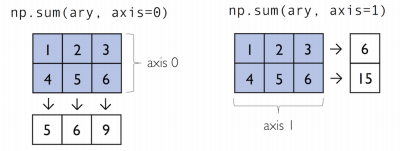

In [12]:
x = np.array([[1,2],[3,4]], dtype=np.float64)
y = np.array([[5,6],[7,8]], dtype=np.float64)
title("x:")
print(x)
title("y:")
print(y)

# Each operator works elementwise and has a function form:
# np.add, np.subtract, np.multiply, np.divide; * is NOT matrix multiplication
title("x + y:")
print(x + y)
title("x - y:")
print(x - y)
title("x * y:")
print(x * y)
title("x / y:")
print(x / y)

# Math functions such as np.sqrt, np.exp and np.log also work elementwise
title("np.sqrt(x):")
print(np.sqrt(x))

# np.sum adds up elements; axis=0 sums each column, axis=1 sums each row
m = np.array([[1,2,3],[4,5,6]])
title("m:")
print(m)
title("np.sum(m):", np.sum(m))
title("np.sum(m, axis=0):", np.sum(m, axis=0))
title("np.sum(m, axis=1):", np.sum(m, axis=1))

x:
[[1. 2.]
 [3. 4.]]
y:
[[5. 6.]
 [7. 8.]]
x + y:
[[ 6.  8.]
 [10. 12.]]
x - y:
[[-4. -4.]
 [-4. -4.]]
x * y:
[[ 5. 12.]
 [21. 32.]]
x / y:
[[0.2        0.33333333]
 [0.42857143 0.5       ]]
np.sqrt(x):
[[1.         1.41421356]
 [1.73205081 2.        ]]
m:
[[1 2 3]
 [4 5 6]]
np.sum(m): 21
np.sum(m, axis=0): [5 7 9]
np.sum(m, axis=1): [ 6 15]


### Your turn: `axis`

`grades` holds the grades of 4 students (rows) in 3 exams (columns). Compute:

* `student_avg`: the average grade of **each student**;
* `exam_max`: the highest grade in **each exam**.

**First predict** the shape of each result, then write the code and run the check cell.

Hint: `axis` is the dimension that is collapsed. Averaging over the exams collapses the columns.

In [13]:
grades = np.array([[90, 80, 70],
                   [60, 75, 90],
                   [85, 95, 90],
                   [70, 65, 99]])

student_avg = None   # replace None with your code
exam_max = None      # replace None with your code

### Check your work

In [14]:
if student_avg is None or exam_max is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert student_avg.shape == (4,), f"expected one average per student, shape (4,), got {student_avg.shape}"
    assert exam_max.shape == (3,), f"expected one maximum per exam, shape (3,), got {exam_max.shape}"
    assert student_avg.tolist() == [80, 75, 90, 78], f"wrong averages: {student_avg}"
    assert exam_max.tolist() == [90, 95, 99], f"wrong maxima: {exam_max}"
    title("Correct! average of each student:", student_avg)
    title("highest grade in each exam:", exam_max)

Not done yet: write your code in the cell above and run it.


In [15]:
# Solution
student_avg = grades.mean(axis=1)   # collapse the columns: one value per row
exam_max = grades.max(axis=0)       # collapse the rows: one value per column

## Matrix operations

Note that `*` is elementwise multiplication, not matrix multiplication. For matrix products use the `@` operator (older code writes the same thing as `np.dot(a, b)` or `a.dot(b)`). Entry $(i, j)$ of $XY$ is row $i$ of $X$ times column $j$ of $Y$:

$$(XY)_{ij} = \sum_k X_{ik} Y_{kj}$$

For the matrices $X$ and $Y$ in the cell below, `x @ y` and `x * y` give

$$
XY = \begin{pmatrix}1 & 2\\ 3 & 4\end{pmatrix}\begin{pmatrix}5 & 6\\ 7 & 8\end{pmatrix}
= \begin{pmatrix}1\cdot5+2\cdot7 & 1\cdot6+2\cdot8\\ 3\cdot5+4\cdot7 & 3\cdot6+4\cdot8\end{pmatrix}
= \begin{pmatrix}19 & 22\\ 43 & 50\end{pmatrix},
\qquad
X \odot Y = \begin{pmatrix}1\cdot5 & 2\cdot6\\ 3\cdot7 & 4\cdot8\end{pmatrix} = \begin{pmatrix}5 & 12\\ 21 & 32\end{pmatrix}
$$

Other common matrix operations:

| Operation | NumPy | Notes |
|---|---|---|
| Transpose | `A.T` | |
| Determinant | `np.linalg.det(A)` | |
| Inverse | `np.linalg.inv(A)` | $A^{-1}A = I$ holds only up to floating-point rounding. |
| Solve a linear system | `np.linalg.solve(A, b)` | Prefer this over `np.linalg.inv(A) @ b`: it is faster and more accurate. |
| Rank | `np.linalg.matrix_rank(A)` | |
| Trace | `np.trace(A)` | Also equals the sum of the eigenvalues. |
| Eigenvalues | `np.linalg.eigvals(A)` | `np.linalg.eig(A)` also returns the eigenvectors. |
| Vector length | `np.linalg.norm(b)` | |

The cell below shows the formula for each operation above its result.

Because results are floating-point numbers, compare them with `np.allclose(a, b)` instead of `==`. For more functions see the [linear algebra documentation](https://numpy.org/doc/stable/reference/routines.linalg.html).

In [16]:
x = np.array([[1,2],[3,4]])
y = np.array([[5,6],[7,8]])
m = np.array([[1,2,3],[4,5,6]])
A = np.array([[1,2,3], [0,1,4], [5,6,0]])
b = np.array([1, 2, 3])

topic("1. Matrix product", r"(XY)_{ij} = \sum_k X_{ik} Y_{kj}")
title("x @ y:")
print(x @ y)

topic("2. Elementwise product", r"(X \odot Y)_{ij} = X_{ij} Y_{ij}")
title("x * y:")
print(x * y)

topic("3. Transpose", r"(M^\top)_{ij} = M_{ji}, \quad \text{shape } (2, 3) \to (3, 2)")
title("m.T:")
print(m.T)

title("\nThe rest uses np.linalg on this A and b:")
title("A:")
print(A)
title("b:", b)

topic("4. Determinant", r"\det(A) \neq 0 \;\Rightarrow\; A \text{ is invertible}")
title("np.linalg.det(A):", np.round(np.linalg.det(A), 6))

topic("5. Inverse", r"A^{-1} A = A A^{-1} = I")
A_inv = np.linalg.inv(A)
title("A_inv = np.linalg.inv(A):")
print(A_inv)

topic("6. Solve a linear system", r"A s = b \;\Rightarrow\; s = A^{-1} b")
s = np.linalg.solve(A, b)
title("s = np.linalg.solve(A, b):", s)
title("A @ s:", A @ s)

topic("7. Rank", r"\operatorname{rank}(A) = \text{number of linearly independent rows}")
title("np.linalg.matrix_rank(A):", np.linalg.matrix_rank(A))

topic("8. Trace", r"\operatorname{tr}(A) = \sum_i A_{ii}")
title("np.trace(A):", np.trace(A))

topic("9. Eigenvalues", r"A v = \lambda v, \quad v \neq 0")
# eigvals returns complex numbers for a non-symmetric matrix; here every imaginary part is 0
title("np.linalg.eigvals(A).real:", np.linalg.eigvals(A).real)

topic("10. Euclidean norm (vector length)", r"\lVert b \rVert = \sqrt{\textstyle\sum_i b_i^2}")
title("np.linalg.norm(b):", np.linalg.norm(b))

**1. Matrix product**

$$(XY)_{ij} = \sum_k X_{ik} Y_{kj}$$

x @ y:
[[19 22]
 [43 50]]


**2. Elementwise product**

$$(X \odot Y)_{ij} = X_{ij} Y_{ij}$$

x * y:
[[ 5 12]
 [21 32]]


**3. Transpose**

$$(M^\top)_{ij} = M_{ji}, \quad \text{shape } (2, 3) \to (3, 2)$$

m.T:
[[1 4]
 [2 5]
 [3 6]]

The rest uses np.linalg on this A and b:
A:
[[1 2 3]
 [0 1 4]
 [5 6 0]]
b: [1 2 3]


... (10 outputs left out)

**9. Eigenvalues**

$$A v = \lambda v, \quad v \neq 0$$

np.linalg.eigvals(A).real: [-5.2296696  -0.02635282  7.25602242]


**10. Euclidean norm (vector length)**

$$\lVert b \rVert = \sqrt{\textstyle\sum_i b_i^2}$$

np.linalg.norm(b): 3.7416573867739413


You can find the full list of mathematical functions provided by numpy in the [documentation](https://numpy.org/doc/stable/reference/routines.math.html).

## Broadcasting

Broadcasting is a powerful mechanism that allows numpy to work with arrays even if their dimensions do not match by when performing arithmetic operations. Frequently we have a smaller array and a larger array, and we want to use the smaller array multiple times to perform some operation on the larger array.



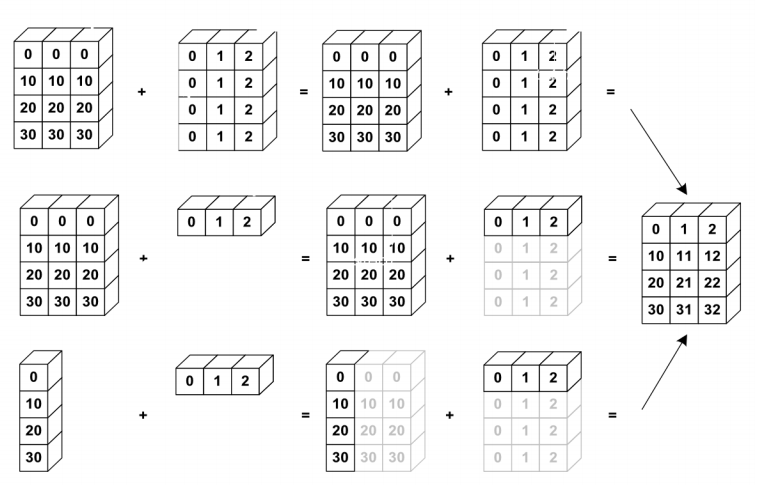

For example, suppose that we want to add a constant vector to each row of a matrix. We could do it like this:

In [17]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = np.empty_like(x)   # Create an empty matrix with the same shape as x

# Add the vector v to each row of the matrix x with an explicit loop
for i in range(4):
    y[i, :] = x[i, :] + v

print(y)

[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


This works; however when the matrix `x` is very large, computing an explicit loop in Python could be slow. Note that adding the vector v to each row of the matrix `x` is equivalent to forming a matrix `vv` by stacking multiple copies of `v` vertically, then performing elementwise summation of `x` and `vv`. We could implement this approach like this:

In [18]:
vv = np.tile(v, (4, 1))   # stack 4 copies of v on top of each other
title("vv = np.tile(v, (4, 1)):")
print(vv)

vv = np.tile(v, (4, 1)):
[[1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]]


In [19]:
y = x + vv
title("y = x + vv:")
print(y)

y = x + vv:
[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


Numpy broadcasting allows us to perform this computation without actually creating multiple copies of v. Consider this version, using broadcasting:

In [20]:
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = x + v   # broadcasting adds v to each row of x without copying v
title("y = x + v:")
print(y)

y = x + v:
[[ 2  2  4]
 [ 5  5  7]
 [ 8  8 10]
 [11 11 13]]


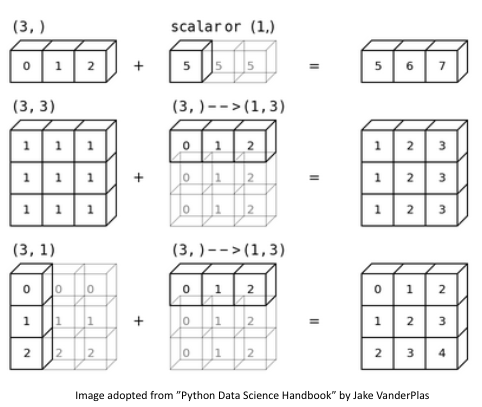

The line `y = x + v` works even though `x` has shape `(4, 3)` and `v` has shape `(3,)` due to broadcasting; this line works as if v actually had shape `(4, 3)`, where each row was a copy of `v`, and the sum was performed elementwise.

Broadcasting two arrays together follows these rules:

1. If the arrays do not have the same rank, prepend the shape of the lower rank array with 1s until both shapes have the same length.
2. The two arrays are said to be compatible in a dimension if they have the same size in the dimension, or if one of the arrays has size 1 in that dimension.
3. The arrays can be broadcast together if they are compatible in all dimensions.
4. After broadcasting, each array behaves as if it had shape equal to the elementwise maximum of shapes of the two input arrays.
5. In any dimension where one array had size 1 and the other array had size greater than 1, the first array behaves as if it were copied along that dimension

If this explanation does not make sense, try reading the explanation from the [documentation](https://numpy.org/doc/stable/user/basics.broadcasting.html).

Functions that support broadcasting are known as universal functions. You can find the list of all universal functions in the [documentation](https://numpy.org/doc/stable/reference/ufuncs.html#available-ufuncs).

Here are some applications of broadcasting:

In [21]:
# Compute outer product of vectors
v = np.array([1,2,3])  # v has shape (3,)
w = np.array([4,5])    # w has shape (2,)
# To compute an outer product, we first reshape v to be a column
# vector of shape (3, 1); we can then broadcast it against w to yield
# an output of shape (3, 2), which is the outer product of v and w:

print(np.reshape(v, (3, 1)) * w)

[[ 4  5]
 [ 8 10]
 [12 15]]


![Outer product by broadcasting](img/broadcast_outer.png)

In [22]:
# Add a vector to each row of a matrix
x = np.array([[1,2,3], [4,5,6]])
# x has shape (2, 3) and v has shape (3,) so they broadcast to (2, 3),
# giving the following matrix:

print(x + v)

[[2 4 6]
 [5 7 9]]


![Adding a vector to each row](img/broadcast_rows.png)

In [23]:
# Add a vector to each column of a matrix
# x has shape (2, 3) and w has shape (2,).
# If we transpose x then it has shape (3, 2) and can be broadcast
# against w to yield a result of shape (3, 2); transposing this result
# yields the final result of shape (2, 3) which is the matrix x with
# the vector w added to each column. Gives the following matrix:

print((x.T + w).T)

[[ 5  6  7]
 [ 9 10 11]]


![Adding a vector to each column](img/broadcast_columns.png)

Broadcasting typically makes your code more concise and faster, so you should strive to use it where possible.

### Your turn: distances with broadcasting

`X` holds 6 points in the plane, one point per row, and `c` is a single point. Without a Python loop, compute:

* `dist`: the Euclidean distance from each point of `X` to `c`, an array of shape `(6,)`;
* `nearest`: the index of the point closest to `c`.

The distance between $x = (x_1, x_2)$ and $c = (c_1, c_2)$ is $\sqrt{(x_1 - c_1)^2 + (x_2 - c_2)^2}$.

Hint: `X - c` broadcasts `c` to every row. Then square, sum over the right axis, and take the square root. `np.argmin` gives the index of the smallest value.

In [24]:
X = np.array([[1, 2],
              [4, 6],
              [0, 0],
              [3, 1],
              [5, 5],
              [2, 3]])
c = np.array([3, 3])

dist = None      # replace None with your code
nearest = None   # replace None with your code

### Check your work

In [25]:
if dist is None or nearest is None:
    print("Not done yet: write your code in the cell above and run it.")
else:
    assert dist.shape == (6,), f"expected one distance per point, shape (6,), got {dist.shape}"
    assert abs(dist[3] - 2.0) < 1e-9 and abs(dist[1] - 10 ** 0.5) < 1e-9, f"wrong distances: {dist}"
    assert nearest == 5, f"expected point 5, got {nearest}"
    title("Correct! distances:", dist.round(3))
    title("nearest point:", nearest, X[nearest])

Not done yet: write your code in the cell above and run it.


In [26]:
# Solution
diff = X - c                               # shape (6, 2): c is subtracted from every row
dist = np.sqrt((diff ** 2).sum(axis=1))    # sum over the coordinates: shape (6,)
nearest = np.argmin(dist)

This brief overview has touched on many of the important things that you need to know about numpy, but is far from complete. Check out the [numpy reference](https://numpy.org/doc/stable/reference/) to find out much more about numpy.

## Random Seeds

In machine learning and deep learning, we often have to generate arrays of random numbers – for example, the initial values of our model parameters before optimization. NumPy
has a random subpackage to create random numbers and samples from a variety of distributions conveniently. Seeds ensures that our results are reproducible.

In [27]:
np.random.seed(593)
print(np.random.rand(3))
print(np.random.rand(3))   # the next numbers in the sequence, so they differ

np.random.seed(593)        # the same seed again ...
print(np.random.rand(3))   # ... gives the same numbers as the first line

[0.1179011  0.76008265 0.61310671]
[0.99767054 0.20766141 0.4758394 ]
[0.1179011  0.76008265 0.61310671]


### Two random APIs

NumPy has two interfaces for random numbers:

* **Legacy:** functions under `np.random.*` that share one global state, seeded with `np.random.seed(...)`.
* **Modern (recommended since NumPy 1.17):** a `Generator` object, `rng = np.random.default_rng(seed)`. Each generator has its own state, so different parts of a program cannot disturb each other's random sequence.

| Task | Legacy `np.random.*` | Generator `rng = np.random.default_rng(seed)` |
|---|---|---|
| Set the seed | `np.random.seed(42)` | `rng = np.random.default_rng(42)` |
| Uniform values in [0, 1) | `np.random.rand(2, 3)` | `rng.random((2, 3))` |
| Standard normal values | `np.random.randn(2, 3)` | `rng.standard_normal((2, 3))` |
| Integers in [lo, hi) | `np.random.randint(0, 10, size=5)` | `rng.integers(0, 10, size=5)` |
| Sample from `a` (optional probabilities `p`) | `np.random.choice(a, size, replace, p)` | `rng.choice(a, size, replace, p)` |
| Shuffle in place | `np.random.shuffle(a)` | `rng.shuffle(a)` |
| Shuffled copy | `np.random.permutation(a)` | `rng.permutation(a)` |

**Important for HW2:** the assignment requires `np.random.seed(1234)` and `np.random.choice()`, and the expected outputs were generated with that legacy stream. Use the left column for HW2.

The two APIs produce **different** sequences even with the same seed:

In [28]:
np.random.seed(1234)
title("legacy:   ", np.random.choice(10, size=5))

rng = np.random.default_rng(1234)
title("generator:", rng.choice(10, size=5))

legacy:    [3 6 5 4 8]
generator: [9 9 9 3 1]


# SciPy

SciPy is a library of scientific algorithms built on NumPy arrays: optimization, statistics, signal processing, sparse matrices and more. We do not use it in this course.

One part is worth knowing for the project: **`scipy.sparse` is what you reach for when the PageRank graph is big.** The link matrix of N web pages has N² entries, but almost all of them are zero, because each page links to only a few others. A sparse matrix stores only the non-zero entries, and still supports the same matrix-vector product `M @ r` that PageRank repeats. See the [scipy.sparse documentation](https://docs.scipy.org/doc/scipy/reference/sparse.html).

# Matplotlib

Matplotlib is the standard plotting library for Python. A plot is built from two objects:

* a **figure** (`fig`): the whole image, which can hold several plots;
* one or more **axes** (`ax`): a single plot inside the figure, with its own x and y axis.

`plt.subplots()` creates both; you then draw on each axes with its methods. The most common ones:

| Task | Code |
|---|---|
| Figure with 1 row of 3 plots | `fig, axes = plt.subplots(1, 3, figsize=(15, 4))` |
| Line plot | `ax.plot(x, y, label=..., color=..., linestyle=...)` |
| Scatter plot | `ax.scatter(x, y, c=values, cmap=...)` |
| Histogram | `ax.hist(data, bins=30)` |
| Title and axis labels | `ax.set_title(...)`, `ax.set_xlabel(...)`, `ax.set_ylabel(...)` |
| Legend and grid | `ax.legend()`, `ax.grid(True)` |
| Horizontal / vertical reference line | `ax.axhline(y)`, `ax.axvline(x)` |
| Colour bar for a scatter plot | `fig.colorbar(points, ax=ax)` |
| Title for the whole figure, fix spacing | `fig.suptitle(...)`, `fig.tight_layout()` |
| Save to a file | `fig.savefig("plot.png", dpi=150)` |

Plotting pandas data with `df.plot` is covered in the pandas lesson. For everything else, see the [Matplotlib documentation](https://matplotlib.org/stable/).

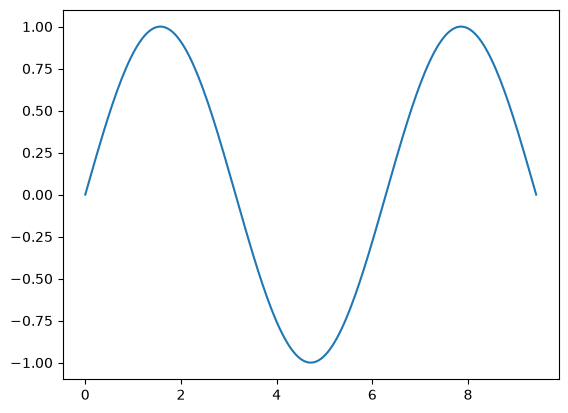

In [29]:
x = np.linspace(0, 3 * np.pi, 200)

fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
plt.show()

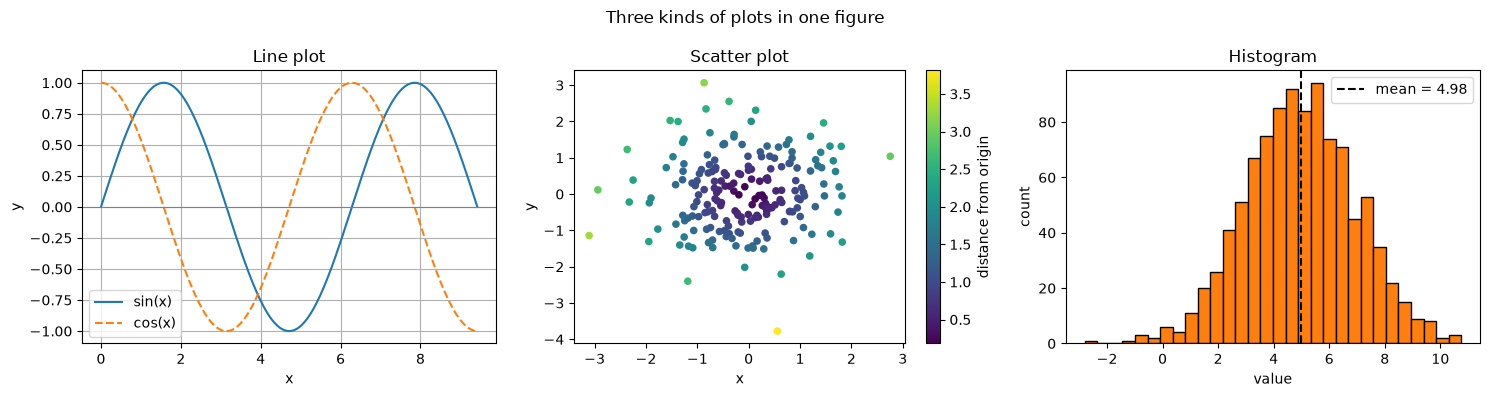

In [30]:
# Three plots side by side: axes is an array of 3 axes, one per plot
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) Line plot: two functions on the same axes, with a legend
axes[0].plot(x, np.sin(x), label="sin(x)")
axes[0].plot(x, np.cos(x), label="cos(x)", linestyle="--")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Line plot")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
axes[0].grid(True)

# 2) Scatter plot: the colour of each point shows a third value
pts = rng.normal(size=(200, 2))
dist = np.linalg.norm(pts, axis=1)          # distance of each point from the origin
points = axes[1].scatter(pts[:, 0], pts[:, 1], c=dist, cmap="viridis", s=20)
fig.colorbar(points, ax=axes[1], label="distance from origin")
axes[1].set_title("Scatter plot")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")

# 3) Histogram: the distribution of 1000 normal samples, with the mean marked
samples = rng.normal(loc=5, scale=2, size=1000)
axes[2].hist(samples, bins=30, color="tab:orange", edgecolor="black")
axes[2].axvline(samples.mean(), color="black", linestyle="--", label=f"mean = {samples.mean():.2f}")
axes[2].set_title("Histogram")
axes[2].set_xlabel("value")
axes[2].set_ylabel("count")
axes[2].legend()

fig.suptitle("Three kinds of plots in one figure")
fig.tight_layout()   # stop titles and labels from overlapping
plt.show()